In [1]:
import os
import gc
import random
import uproot
import h5py
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

File miniSPINE_DATA/minispine_test.h5 già presente su disco.
Dispositivo di esecuzione: cuda


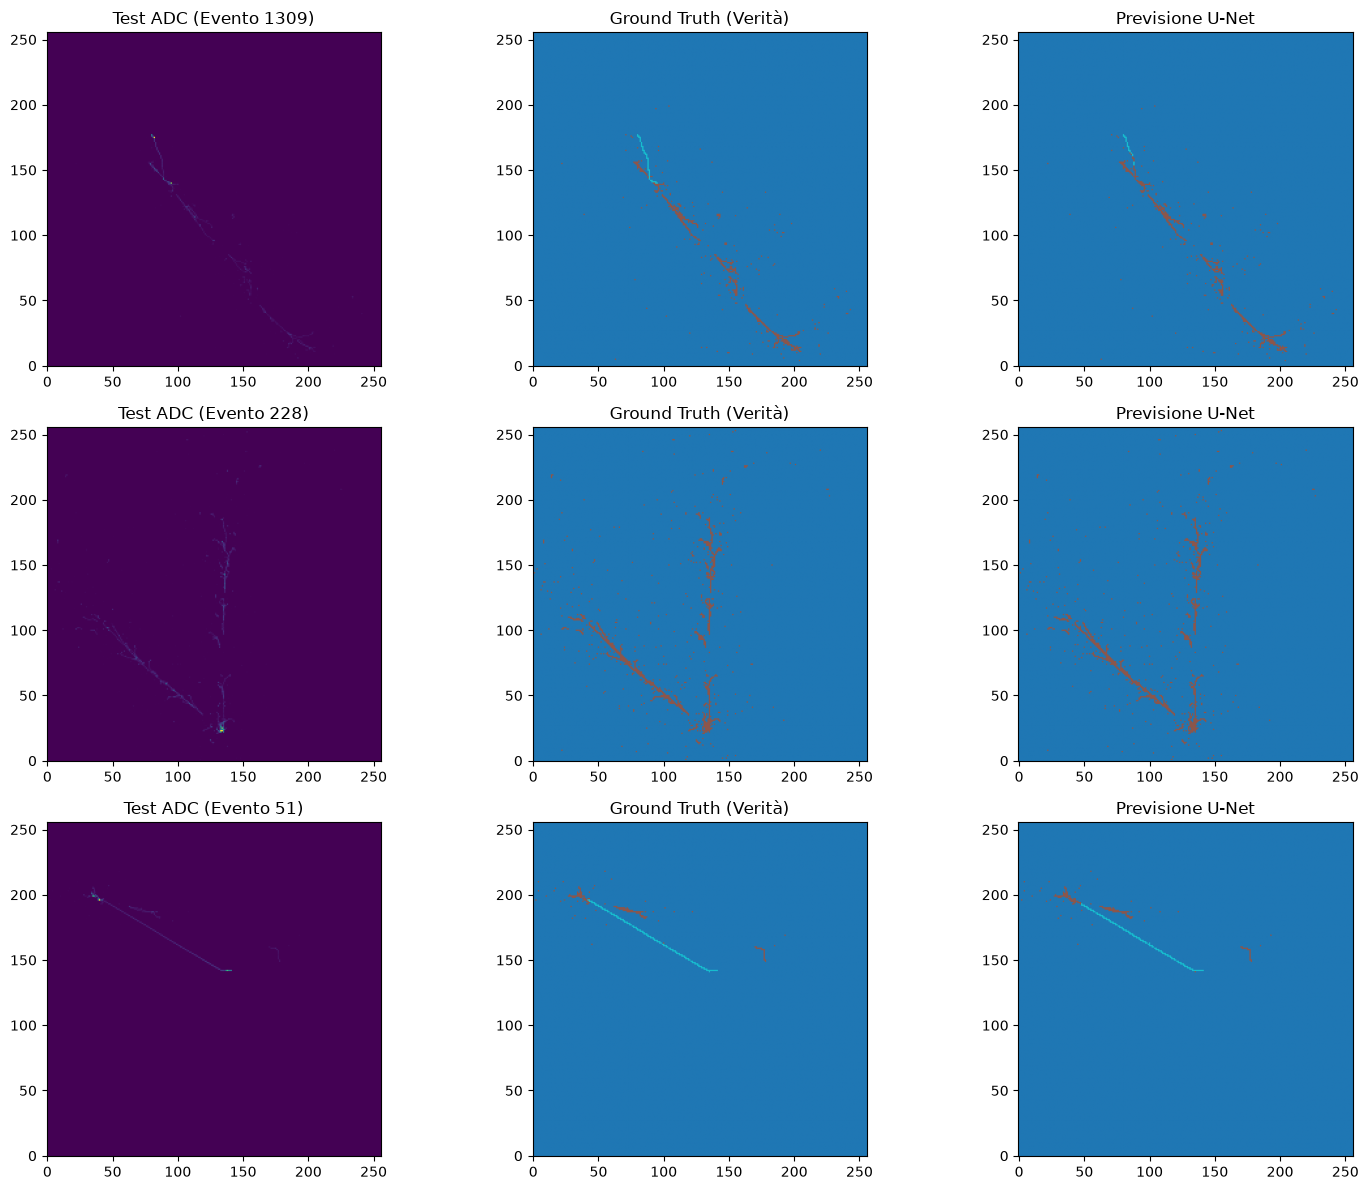

Calcolo matrice di confusione progressivo...


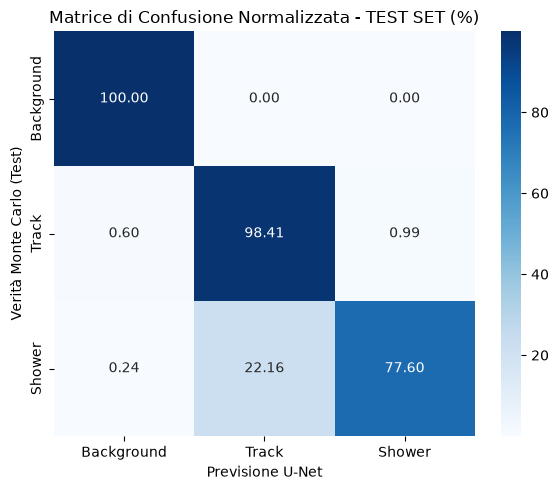

In [2]:
# =====================================================================
# 1. DEFINIZIONE ARCHITETTURA (MiniUNet)
# =====================================================================
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.double_conv(x)

class MiniUNet(nn.Module):
    def __init__(self, n_channels=1, n_classes=3):
        super(MiniUNet, self).__init__()
        self.inc = DoubleConv(n_channels, 16)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(16, 32))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(128, 64)
        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(64, 32)
        self.up3 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.conv_up3 = DoubleConv(32, 16)
        self.outc = nn.Conv2d(16, n_classes, kernel_size=1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x = self.up1(x4)
        x = torch.cat([x3, x], dim=1)
        x = self.conv_up1(x)
        x = self.up2(x)
        x = torch.cat([x2, x], dim=1)
        x = self.conv_up2(x)
        x = self.up3(x)
        x = torch.cat([x1, x], dim=1)
        x = self.conv_up3(x)
        return self.outc(x)

# =====================================================================
# 2. CONVERSIONE CON SCRITTURA DIRETTA SU DISCO (ZERO BUFFER IN RAM)
# =====================================================================
root_test_path = "miniSPINE_DATA/practice_test_2k.root"
h5_test_path = "miniSPINE_DATA/minispine_test.h5"

os.makedirs("miniSPINE_DATA", exist_ok=True)

# Se il file non esiste, lo crea scrivendo direttamente su file aperto su disco
if not os.path.exists(h5_test_path):
    print(f"Creazione del file HDF5 su disco: {h5_test_path}")
    file = uproot.open(root_test_path)
    data_tree = file["image2d_data_tree"]
    seg_tree = file["image2d_segment_tree"]

    rows = int(data_tree["_image_v._meta._row_count"].array(library="np")[0][0])
    cols = int(data_tree["_image_v._meta._col_count"].array(library="np")[0][0])

    n_events = 2000

    with h5py.File(h5_test_path, 'w') as hf:
        # Dataset espandibili su disco: nessun array complessivo in RAM
        img_ds = hf.create_dataset('images', shape=(0, rows, cols), maxshape=(None, rows, cols),
                                   dtype=np.float32, compression="gzip", chunks=(1, rows, cols))
        mask_ds = hf.create_dataset('masks', shape=(0, rows, cols), maxshape=(None, rows, cols),
                                    dtype=np.int64, compression="gzip", chunks=(1, rows, cols))

        saved_count = 0

        # Scorre un evento alla volta tramite uproot senza accumulare
        for i in range(n_events):
            seg_single = seg_tree["_image_v._img"].array(library="np", entry_start=i, entry_stop=i+1)
            mask_2d = np.array(seg_single[0][0]).reshape(rows, cols)

            if np.max(mask_2d) > 0:
                data_single = data_tree["_image_v._img"].array(library="np", entry_start=i, entry_stop=i+1)
                img_2d = np.array(data_single[0][0]).reshape(rows, cols)

                # Estende il dataset su disco di 1 posizione e scrive direttamente
                img_ds.resize((saved_count + 1, rows, cols))
                mask_ds.resize((saved_count + 1, rows, cols))

                img_ds[saved_count] = img_2d.astype(np.float32)
                mask_ds[saved_count] = mask_2d.astype(np.int64)

                saved_count += 1
                del data_single, img_2d

            del seg_single, mask_2d

            if (i + 1) % 100 == 0:
                print(f"Scansionati {i + 1}/{n_events} eventi ROOT | Salvati su disco: {saved_count}")
                gc.collect()

    print(f"Completato! Salvati {saved_count} eventi validi direttamente in {h5_test_path}.")
else:
    print(f"File {h5_test_path} già presente su disco.")

# =====================================================================
# 3. DATASET AD ACCESSO DIRETTO SU DISCO (HDF5 POINTER)
# =====================================================================
class DiskSPINEDataset(Dataset):
    def __init__(self, h5_file_path):
        self.path = h5_file_path
        with h5py.File(self.path, 'r') as hf:
            self.total_records = len(hf['images'])
        self.file_handle = None

    def __len__(self):
        return self.total_records

    def __getitem__(self, idx):
        # Mantiene solo il descrittore file aperto; legge unicamente i byte dell'evento idx
        if self.file_handle is None:
            self.file_handle = h5py.File(self.path, 'r')
            
        img = self.file_handle['images'][idx]
        mask = self.file_handle['masks'][idx]

        # Creazione del tensore float senza allocazioni intermedie
        img_tensor = torch.from_numpy(img[None, :, :]).float()
        mask_tensor = torch.from_numpy(mask).long()

        return img_tensor, mask_tensor

# =====================================================================
# 4. CARICAMENTO MODELLO ED INFERENZA
# =====================================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo di esecuzione: {device}")

model = MiniUNet(n_channels=1, n_classes=3).to(device)
weights_path = "miniSPINE_unet_weights.pth"
model.load_state_dict(torch.load(weights_path, map_location=device, weights_only=True))
model.eval()

test_dataset = DiskSPINEDataset(h5_test_path)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=0)

# =====================================================================
# 5. VISUALIZZAZIONE DI 3 EVENTI CASUALI
# =====================================================================
random.seed(42)
sampled_indices = random.sample(range(len(test_dataset)), 3)

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for row_idx, ev_idx in enumerate(sampled_indices):
    img_t, mask_t = test_dataset[ev_idx]

    with torch.no_grad():
        out = model(img_t.unsqueeze(0).to(device))
        pred_map = torch.argmax(out, dim=1).squeeze(0).cpu().numpy()

    img_raw = img_t.squeeze(0).numpy()
    mask_truth = mask_t.numpy()

    # Colonna 1: Input ADC
    axes[row_idx, 0].imshow(img_raw, cmap='viridis', origin='lower')
    axes[row_idx, 0].set_title(f"Test ADC (Evento {ev_idx})")

    # Colonna 2: Verità Ground Truth
    axes[row_idx, 1].imshow(mask_truth, cmap='tab10', origin='lower', vmin=0, vmax=2)
    axes[row_idx, 1].set_title("Ground Truth (Verità)")

    # Colonna 3: Predizione U-Net
    axes[row_idx, 2].imshow(pred_map, cmap='tab10', origin='lower', vmin=0, vmax=2)
    axes[row_idx, 2].set_title("Previsione U-Net")

plt.tight_layout()
plt.show()
plt.close(fig)

# =====================================================================
# 6. MATRICE DI CONFUSIONE AGGREGATA SUL DISCO
# =====================================================================
print("Calcolo matrice di confusione progressivo...")
total_cm = torch.zeros((3, 3), dtype=torch.int64)

with torch.no_grad():
    for batch_imgs, batch_masks in test_loader:
        batch_imgs = batch_imgs.to(device)
        preds = torch.argmax(model(batch_imgs), dim=1).cpu()

        # Calcolo istantaneo delle occorrenze 3x3 senza salvare i pixel
        linear_idx = 3 * batch_masks.view(-1) + preds.view(-1)
        total_cm += torch.bincount(linear_idx, minlength=9).reshape(3, 3)

cm_norm = (total_cm.float() / total_cm.sum(dim=1, keepdim=True) * 100).numpy()

fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=["Background", "Track", "Shower"],
            yticklabels=["Background", "Track", "Shower"],
            ax=ax_cm)
ax_cm.set_ylabel('Verità Monte Carlo (Test)')
ax_cm.set_xlabel('Previsione U-Net')
ax_cm.set_title('Matrice di Confusione Normalizzata - TEST SET (%)')
plt.tight_layout()
plt.show()
plt.close(fig_cm)

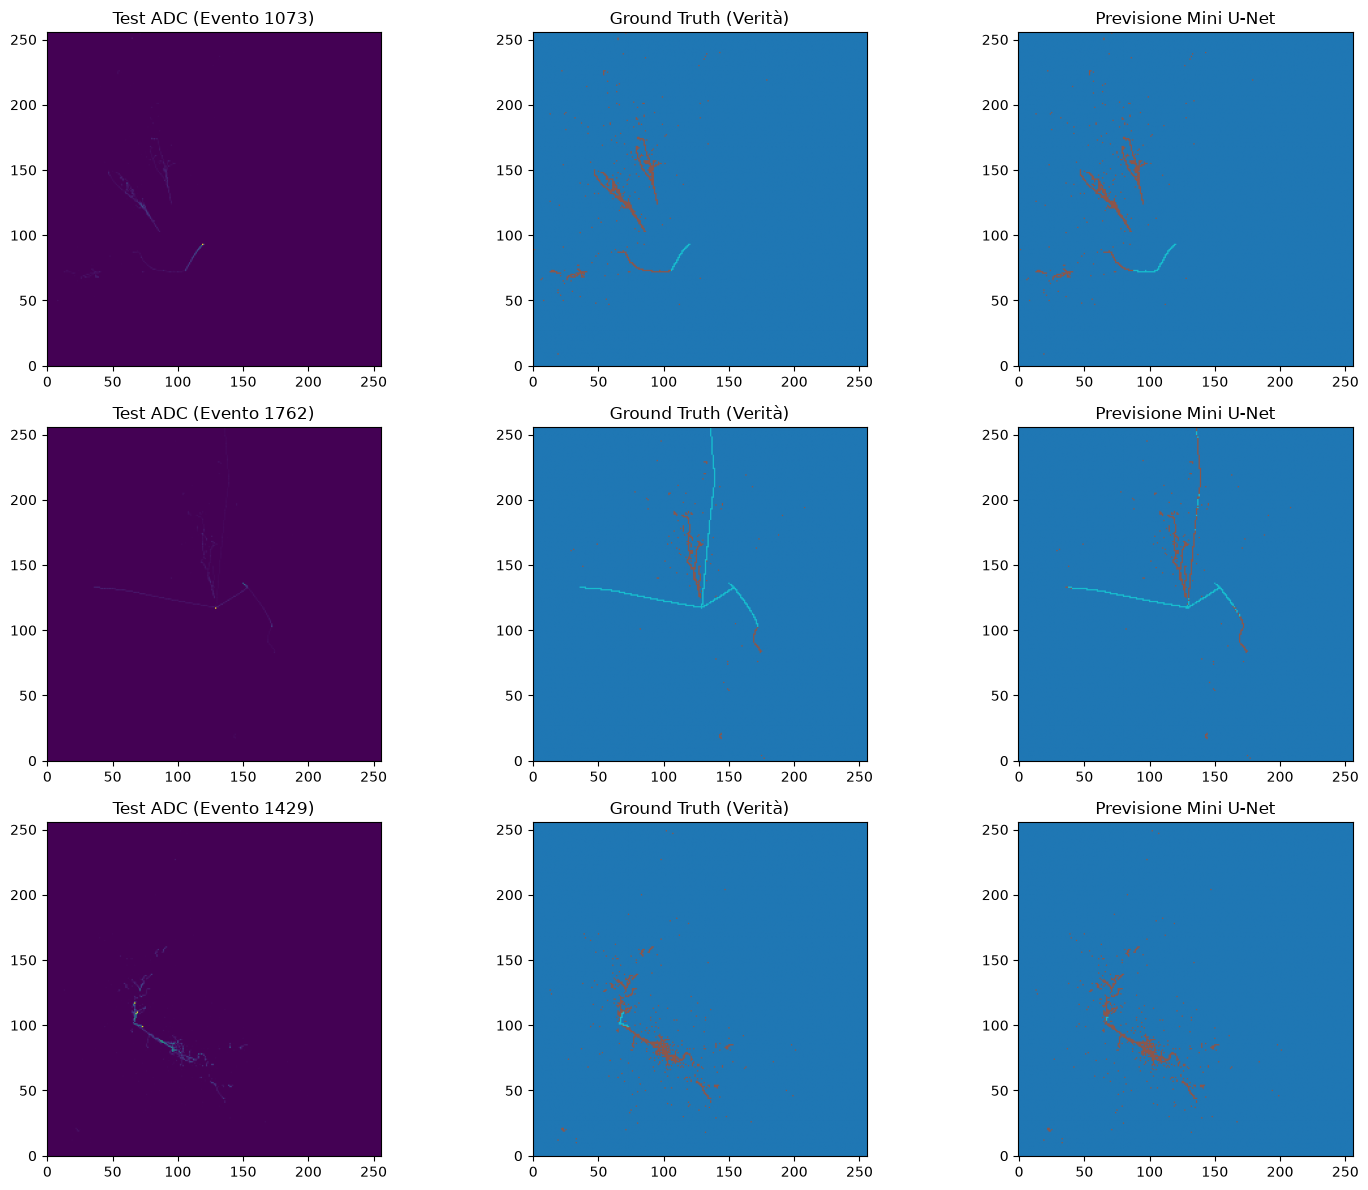

In [3]:
model.eval()

# 1. Estrazione di 3 indici casuali dal test dataset
n_views = 3
rand_indices = np.random.choice(len(test_dataset), n_views, replace=False)

fig, axes = plt.subplots(n_views, 3, figsize=(15, 4 * n_views))

for row, idx in enumerate(rand_indices):
    img_t, mask_t = test_dataset[idx]
    
    # Inferenza sul singolo evento
    with torch.no_grad():
        out = model(img_t.unsqueeze(0).to(device))
        pred_label = torch.argmax(out, dim=1).squeeze(0).cpu().numpy()

    img_raw = img_t.squeeze(0).numpy()
    mask_truth = mask_t.numpy()

    # Colonna 1: Input ADC Grezzo
    axes[row, 0].imshow(img_raw, cmap='viridis', origin='lower')
    axes[row, 0].set_title(f"Test ADC (Evento {idx})")

    # Colonna 2: Verità Ground Truth
    axes[row, 1].imshow(mask_truth, cmap='tab10', origin='lower', vmin=0, vmax=2)
    axes[row, 1].set_title("Ground Truth (Verità)")

    # Colonna 3: Previsione U-Net
    axes[row, 2].imshow(pred_label, cmap='tab10', origin='lower', vmin=0, vmax=2)
    axes[row, 2].set_title("Previsione Mini U-Net")

plt.tight_layout()
plt.show()
plt.close(fig)